In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
bike_df = pd.read_csv("../../datasets/raw/bike_sharing/hour.csv")

# Create cyclic hour features
bike_df["hour_sin"] = np.sin(2 * np.pi * bike_df["hr"] / 24)
bike_df["hour_cos"] = np.cos(2 * np.pi * bike_df["hr"] / 24)

# Select features
features = ["hour_sin", "hour_cos", "temp", "hum", "windspeed"]
X = bike_df[features]

# Standardize
X_scaled = ((X - X.mean()) / X.std()).to_numpy()

print("Data shape:", X_scaled.shape)

Data shape: (17379, 5)


In [2]:
def kmeans(X, k, max_iters=100, n_init=10, random_state=42):

    best_wcss = float("inf")
    best_labels = None
    best_centroids = None

    rng = np.random.default_rng(random_state)

    for run in range(n_init):

        # Step 1: Randomly initialize K centroids
        indices = rng.choice(len(X), size=k, replace=False)
        centroids = X[indices].copy()

        for iteration in range(max_iters):

            # Step 2: Calculate squared distances
            distances = np.sum(
                (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
                axis=2
            )

            # Step 3: Assign each point to nearest centroid
            labels = np.argmin(distances, axis=1)

            # Step 4: Update centroids
            new_centroids = np.zeros((k, X.shape[1]))

            for cluster in range(k):
                cluster_points = X[labels == cluster]

                if len(cluster_points) > 0:
                    new_centroids[cluster] = cluster_points.mean(axis=0)
                else:
                    # Handle empty cluster
                    new_centroids[cluster] = X[rng.integers(len(X))]

            # Step 5: Check convergence
            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break

            centroids = new_centroids

        # Calculate final WCSS
        final_distances = np.sum(
            (X - centroids[labels]) ** 2,
            axis=1
        )

        wcss = np.sum(final_distances)

        # Keep the best initialization
        if wcss < best_wcss:
            best_wcss = wcss
            best_labels = labels.copy()
            best_centroids = centroids.copy()

    return best_labels, best_centroids, best_wcss

In [3]:
labels, centroids, wcss = kmeans(
    X_scaled,
    k=3
)

print("Number of clusters:", len(np.unique(labels)))
print("Centroid shape:", centroids.shape)
print("WCSS:", wcss)

print("\nCluster distribution:")
print(pd.Series(labels).value_counts().sort_index())

Number of clusters: 3
Centroid shape: (3, 5)
WCSS: 55764.06603560097

Cluster distribution:
0    5851
1    5824
2    5704
Name: count, dtype: int64


In [4]:
k_values = [2, 3, 4, 5, 6]
wcss_values = []

for k in k_values:

    labels, centroids, wcss = kmeans(
        X_scaled,
        k=k,
        max_iters=100,
        n_init=10,
        random_state=42
    )

    wcss_values.append(wcss)

    print(f"K = {k}, WCSS = {wcss:.2f}")

K = 2, WCSS = 65562.23
K = 3, WCSS = 55764.07
K = 4, WCSS = 49113.85
K = 5, WCSS = 45186.36
K = 6, WCSS = 41696.01


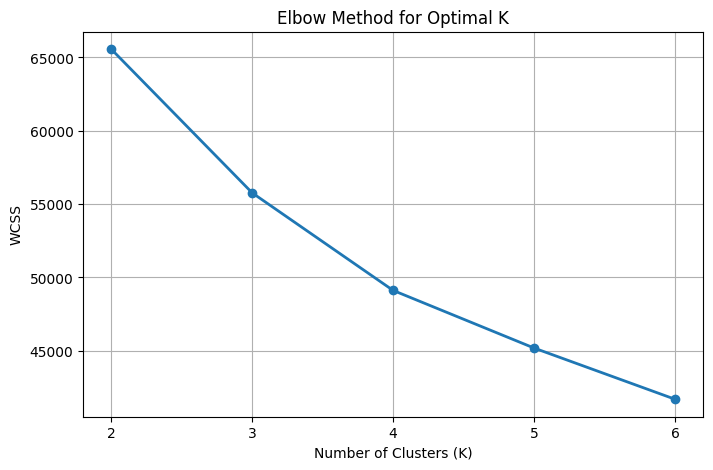

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    wcss_values,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [6]:
wcss_results = pd.DataFrame({
    "K": k_values,
    "WCSS": wcss_values
})

display(wcss_results)

wcss_results.to_csv(
    "kmeans_elbow_results.csv",
    index=False
)

,K,WCSS
0,2,65562.233048
1,3,55764.066036
2,4,49113.846358
3,5,45186.362219
4,6,41696.014555


In [7]:
optimal_k = 4

final_labels, final_centroids, final_wcss = kmeans(
    X_scaled,
    k=optimal_k,
    max_iters=100,
    n_init=10,
    random_state=42
)

print("Optimal K:", optimal_k)
print("Final WCSS:", final_wcss)
print("Centroid shape:", final_centroids.shape)

print("\nCluster distribution:")
print(
    pd.Series(final_labels)
    .value_counts()
    .sort_index()
)

Optimal K: 4
Final WCSS: 49113.846357622104
Centroid shape: (4, 5)

Cluster distribution:
0    4970
1    3901
2    3454
3    5054
Name: count, dtype: int64


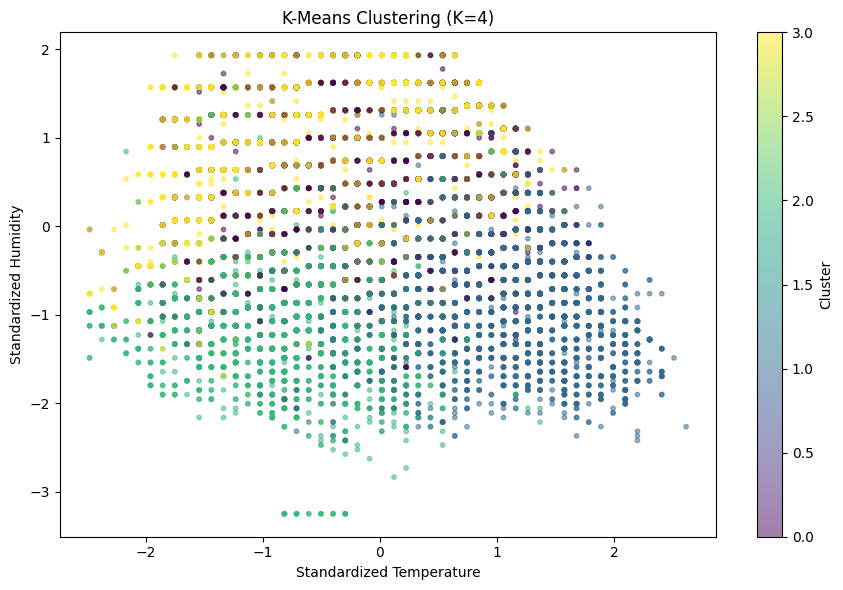

In [8]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3],
    c=final_labels,
    cmap="viridis",
    alpha=0.5,
    s=10
)

plt.xlabel("Standardized Temperature")
plt.ylabel("Standardized Humidity")
plt.title("K-Means Clustering (K=4)")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()